### 5 - Exercise

* On the test sample, evaluate the impact of the two elastic net parameters on out-of-sample accuracy.
* I'll use MSE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.chdir(r'C:\Users\ferna\OneDrive\Downloads\GitHub\ml_factorinv')

In [34]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="With alpha=0.*", category=UserWarning)
warnings.filterwarnings("ignore", message="Coordinate descent with no regularization.*", category=UserWarning)

In [35]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet

In [36]:
from data.data_load import *

In [37]:
# Values of alpha and lambda
from itertools import product
alphas = np.linspace(0,1,10)
lambdas = np.linspace(1e-13,1e-5,35)
params = list(product(alphas, lambdas))
#print(params)

In [38]:
y_penalized_train = data_ml.loc[idx_train,:]['R1M_Usd'].values # Dependent variable
X_penalized_train = data_ml.loc[idx_train,:][features_short].values  # Predictors
y_penalized_test = data_ml.loc[idx_test,:]['R1M_Usd'].values # Dependent variable
X_penalized_test = data_ml.loc[idx_test,:][features_short].values # Predictors
mse_dict = {}

In [39]:
# Ridge (alpha=0) does not converge for low values. You can add more iterations in such cases.
for alpha, lambda_ in params:
    print(alpha,lambda_)
    model = ElasticNet(alpha=alpha, l1_ratio=lambda_,max_iter=5000)
    fir_pen_pred=model.fit(X_penalized_train,y_penalized_train) 
    mse = np.mean((fir_pen_pred.predict(X_penalized_test) - y_penalized_test)**2)
    mse_dict[(alpha,lambda_)] = mse

0.0 1e-13
0.0 2.9411774411764706e-07
0.0 5.882353882352942e-07
0.0 8.823530323529413e-07
0.0 1.1764706764705882e-06
0.0 1.4705883205882353e-06
0.0 1.7647059647058824e-06
0.0 2.0588236088235292e-06
0.0 2.3529412529411765e-06
0.0 2.647058897058824e-06
0.0 2.9411765411764707e-06
0.0 3.2352941852941175e-06
0.0 3.529411829411765e-06
0.0 3.823529473529412e-06
0.0 4.1176471176470585e-06
0.0 4.411764761764706e-06
0.0 4.705882405882353e-06
0.0 5.00000005e-06
0.0 5.294117694117648e-06
0.0 5.588235338235294e-06
0.0 5.882352982352941e-06
0.0 6.176470626470589e-06
0.0 6.470588270588235e-06
0.0 6.764705914705882e-06
0.0 7.05882355882353e-06
0.0 7.352941202941177e-06
0.0 7.647058847058824e-06
0.0 7.941176491176472e-06
0.0 8.235294135294117e-06
0.0 8.529411779411764e-06
0.0 8.823529423529412e-06
0.0 9.117647067647059e-06
0.0 9.411764711764706e-06
0.0 9.705882355882354e-06
0.0 1e-05
0.1111111111111111 1e-13
0.1111111111111111 2.9411774411764706e-07
0.1111111111111111 5.882353882352942e-07
0.11111111111

In [40]:
mse_df = pd.Series(mse_dict, name='mse').rename_axis(['alpha', 'lambda']).reset_index()
mse_df.loc[mse_df['mse'].idxmin()]

alpha     0.222222
lambda    0.000010
mse       0.036980
Name: 104, dtype: float64

In [41]:
mse_matrix = mse_df.pivot(
    index='alpha',
    columns='lambda',
    values='mse'
)

In [42]:
mse_matrix

lambda,1.000000e-13,2.941177e-07,5.882354e-07,8.823530e-07,1.176471e-06,1.470588e-06,1.764706e-06,2.058824e-06,2.352941e-06,2.647059e-06,...,7.352941e-06,7.647059e-06,7.941176e-06,8.235294e-06,8.529412e-06,8.823529e-06,9.117647e-06,9.411765e-06,9.705882e-06,1.000000e-05
alpha,,,,,,,,,,,,,,,,,,,,,
0.000000,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,...,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013,0.037013
0.111111,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,...,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981
0.222222,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,...,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980,0.036980
0.333333,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,...,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981,0.036981
0.444444,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,...,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982,0.036982
0.555556,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,...,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984,0.036984
0.666667,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,...,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985,0.036985
0.777778,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,...,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986,0.036986
0.888889,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,...,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987,0.036987


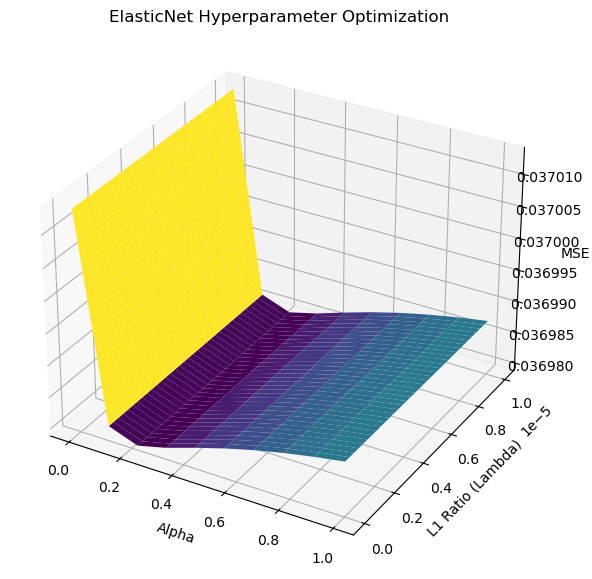

In [44]:
import matplotlib.pyplot as plt
import numpy as np

from mpl_toolkits.mplot3d import Axes3D

Alpha, Lambda = np.meshgrid(alphas, lambdas, indexing='ij')

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(Alpha, Lambda, mse_matrix, cmap='viridis')

ax.set_xlabel('Alpha')
ax.set_ylabel('L1 Ratio (Lambda)')
ax.set_zlabel('MSE')
ax.set_title('ElasticNet Hyperparameter Optimization')

plt.show()